## Datasci 530 - Assignment 4
### Processing Data Using Regular Expressions

Joelle Millar
October 2026


## Overview

This assignment analyses congressional bill actions using the `bills_actions.csv` dataset. It begins by examining the distribution of bills and recorded actions across categories and main action types.

Regular expressions are then used to extract legislators' names from unstructured action descriptions. The analysis focuses on House floor actions associated with Senate bills, including suspension procedures and the frequency with which individual representatives are mentioned. It also examines Senate amendment actions to identify the senators mentioned, measure patterns of coauthorship, and explore differences in bill activity. 

Finally, an additional analysis investigates the relationship between the number of senators mentioned and the total number of recorded actions associated with a bill. These analyses demonstrate how regular expression and data manipulation can be used to extract meaningful information from unstructured text.

### Key Findings

The dataset contains 1,494 distinct bills. The most common category was amendment, accounting for 46.3% of all recorded actions, while the most common main action was house floor actions, representing 30.9% of recorded actions.

Of the 116 House floor actions associated with Senate bills, 69% involved suspending the rules, and 15.5% involved suspending the rules as amended. The name extraction identified 53 unique individuals mentioned in these action descriptions.

Across 131 distinct bills in the Senate amendment subset, the number of distinct senators mentioned per bill ranged from 1 to 29. Most bills (75.6%) mentioned two senators. McConnell was associated with the largest number of distinct second-senator coauthors, with 37 different coauthors. 

In the additional analysis, bills mentioning one or two distinct senators had a median of two recorded actions overall. Bills mentioning three or more senators generally had higher median action counts, although these groups contained very few bills. The bill wuth 38 distinct senators had 187 recorded actions, which substantially increases the mean for this group. Overall the results suggest a possible association between the number of distinct senators mentioned and recorded bill activity. However, the small group sizes and extreme values mean that the analysis does not establish a causal relationship.

### Set Up & Data Cleaning

In [113]:
import pandas as pd
import matplotlib.pyplot as plt

In [114]:
# Load the original dataset
bills_actions = pd.read_csv("data_raw/bills_actions.csv")

# Create a unique identifier for each bill
# Bill numbers can repeat across Congresses or bill types
bills_actions["bill"] = (
    bills_actions["Congress"].astype(str) + "-"
    + bills_actions["bill_type"].astype(str) + "-"
    + bills_actions["bill_number"].astype(str)
)

print(f"Number of rows: {len(bills_actions):,}")
print(f"Number of columns: {bills_actions.shape[1]}")

# Check missing values and duplicate rows
display(
    bills_actions.isna().sum()
    .rename("Missing values")
    .to_frame()
    .query("`Missing values` > 0")
)
print(f"Number of duplicate rows: {bills_actions.duplicated().sum():,}")

# Inspect the categories and main actions available in the dataset
display(bills_actions["category"].value_counts(dropna=False).to_frame())
display(bills_actions["main_action"].value_counts(dropna=False).head(10).to_frame())

Number of rows: 3,303
Number of columns: 8


,Missing values


Number of duplicate rows: 49


,count
category,
amendment,1529
house bill,902
senate bill,514
house resolution,234
senate resolution,60
house joint resolution,22
house concurrent resolution,20
senate concurrent resolution,14
senate joint resolution,8


,count
main_action,
house floor actions,1020
house amendment offered,828
senate committee/subcommittee actions,434
other house amendment actions,397
senate amendment proposed (on the floor),286
house committee/subcommittee actions,218
reported to senate,36
senate committee report filed after reporting,33
other senate amendment actions,18


### 1. Descriptive Statistics from the dataset.

- The number of distinct “bill” identifiers there are. 
- The proportion of rows belonging to each category. 
- The proportion of rows belonging to “main_action”.

In [115]:
# The number of distinct 'bill' identifiers

print(f"Number of distinct bills: {bills_actions['bill'].nunique():,}")

# Calculate the number and proportion of rows in each category

category_table = (
    bills_actions["category"]
    .value_counts(dropna=False)
    .rename_axis("Category")
    .reset_index(name="Number of rows")
)

category_table["Percentage"] = (
    category_table["Number of rows"] / len(bills_actions) * 100
)

# Display the results

display(
    category_table.style
    .format({"Percentage": "{:.1f}%"})
    .hide(axis="index")
    .set_caption("Distribution of recorded actions by category")
)


Number of distinct bills: 1,494


Category,Number of rows,Percentage
amendment,1529,46.3%
house bill,902,27.3%
senate bill,514,15.6%
house resolution,234,7.1%
senate resolution,60,1.8%
house joint resolution,22,0.7%
house concurrent resolution,20,0.6%
senate concurrent resolution,14,0.4%
senate joint resolution,8,0.2%


Main action,Number of rows,Percentage
house floor actions,1020,30.9%
house amendment offered,828,25.1%
senate committee/subcommittee actions,434,13.1%
other house amendment actions,397,12.0%
senate amendment proposed (on the floor),286,8.7%
house committee/subcommittee actions,218,6.6%
reported to senate,36,1.1%
senate committee report filed after reporting,33,1.0%
other senate amendment actions,18,0.5%
resolving differences -- house actions,14,0.4%


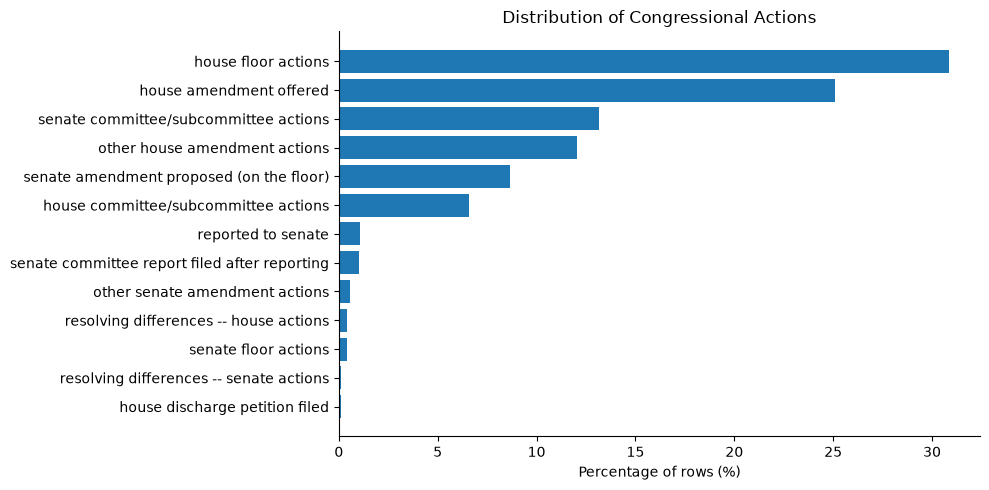

In [116]:
# Calculate the number and percentage of rows for each main action

action_table = (
    bills_actions["main_action"]
    .value_counts(dropna=False)
    .rename_axis("Main action")
    .reset_index(name="Number of rows")
)

action_table["Percentage"] = (
    action_table["Number of rows"] / len(bills_actions) * 100
)

# Display the results

display(
    action_table.style
    .format({"Percentage": "{:.1f}%"})
    .hide(axis="index")
    .set_caption("Distribution of recorded actions by main action")
)

# Plot the distribution using a horizontal bar chart

plot_data = action_table.sort_values("Percentage")

fig, ax = plt.subplots(figsize=(10, max(5, len(plot_data) * 0.35)))
ax.barh(plot_data["Main action"], plot_data["Percentage"])

ax.set_xlabel("Percentage of rows (%)")
ax.set_ylabel("")
ax.set_title("Distribution of Congressional Actions")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### 2. The number of House Floor actions associated with bills in the "Senate bills" category.

- The proportion of these actions that were suspended.
- The proportion of these actions that were suspended as amended.
- The number of bills mentioning the same person and a unique list of the people mentioned.
- The distribution total of distinct bills mentioning each person.


In [117]:
# Select House floor actions associated with Senate bills

senate_bills = bills_actions[
    bills_actions["category"].eq("senate bill")
].copy()

hf_bills = senate_bills[
    senate_bills["main_action"].eq("house floor actions")
].copy()

# Display the results 

print(f"Number of House Floor Actions that are associated with bills in the 'Senate Bills' category: {len(hf_bills)}")
print(f"Number of distinct bills represented: {hf_bills['bill'].nunique():,}")


Number of House Floor Actions that are associated with bills in the 'Senate Bills' category: 116
Number of distinct bills represented: 115


In [118]:
# Search the action descriptions for suspension-related wording
# Case-insensitive matching handles difference in capitalisation

suspended_mask = hf_bills["action"].str.contains(
    r"\bsuspend the rules\b",
    case=False,
    na=False,
    regex=True
)

suspended_amended_mask = hf_bills["action"].str.contains(
    r"\bsuspend the rules\b.*\bas amended\b",
    case=False,
    na=False,
    regex=True
)

# Summarise the results

suspension_results = pd.DataFrame({
    "Measure": [
        "Suspended the rules",
        "Suspended the rules as amended"
    ],
    "Number of actions": [
        suspended_mask.sum(),
        suspended_amended_mask.sum()
    ],
    "Percentage of House floor actions": [
        suspended_mask.mean() * 100,
        suspended_amended_mask.mean() * 100
    ]
})

# Display the results

display(
    suspension_results.style
    .format({"Percentage of House floor actions": "{:.1f}%"})
    .hide(axis="index")
    .set_caption("Suspension of House Floor Actions Associated with Senate Bills")
)

Measure,Number of actions,Percentage of House floor actions
Suspended the rules,80,69.0%
Suspended the rules as amended,18,15.5%


In [119]:
# Extract names following titles such as Mr., Ms., Mrs., and Miss
# This pattern captures one or more capitalised name components

person_pattern = (
    r"\b(?:Mr|Ms|Mrs|Miss)\.\s+"
    r"([A-Z][A-Za-z'-]*(?:\s+[A-Z][A-Za-z'-]*)*)"
)

hf_bills["people_mentioned"] = hf_bills["action"].str.findall(
    person_pattern
)

In [120]:
# Turn each extracted list of names into a separate row

people_long = (
    hf_bills[["bill", "people_mentioned"]]
    .explode("people_mentioned")
    .dropna(subset=["people_mentioned"])
    .rename(columns={"people_mentioned": "Person"})
)

# Count a bill only once per person, even if the person is
# mentioned multiple times in that bill's action records

person_bill_counts = (
    people_long[["bill", "Person"]]
    .drop_duplicates()
    .groupby("Person")["bill"]
    .nunique()
    .reset_index(name="Number of bills")
    .sort_values("Number of bills", ascending=False)
)

display(person_bill_counts.head(20))

# Unique list of extracted names

unique_people = sorted(people_long["Person"].dropna().unique())

print(f"Number of unique extracted names: {len(unique_people):,}")

,Person,Number of bills
48,Takano,9
21,Haaland,6
15,Dingell,6
1,Bass,5
25,Kelly,5
3,Case,5
39,Pallone,5
23,Huffman,4
38,Norton,4
13,DeFazio,4


Number of unique extracted names: 53


,Number of bills mentioning a person,Number of people
0,1,29
1,2,10
2,3,3
3,4,4
4,5,4
5,6,2
6,9,1


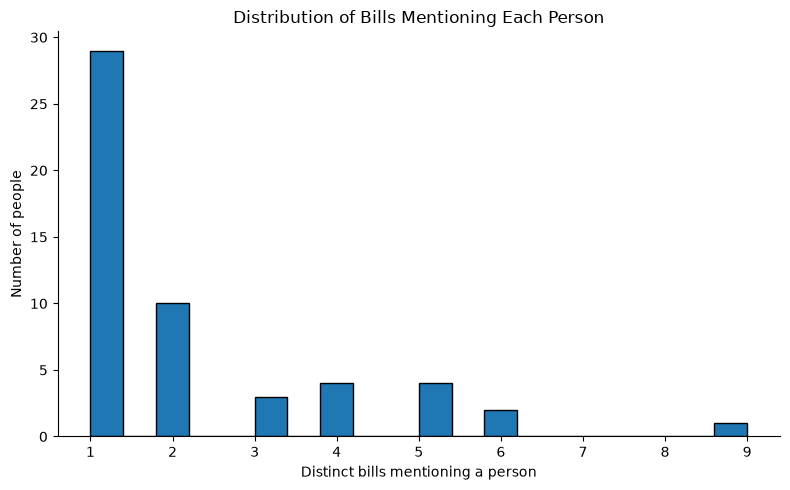

In [121]:
# Count how many people fall into each bill-count category

person_bill_distribution = (
    person_bill_counts["Number of bills"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of bills mentioning a person")
    .reset_index(name="Number of people")
)

# Display the results

display(person_bill_distribution)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    person_bill_counts["Number of bills"],
    bins=20,
    edgecolor="black"
)

ax.set_xlabel("Distinct bills mentioning a person")
ax.set_ylabel("Number of people")
ax.set_title("Distribution of Bills Mentioning Each Person")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### 3. Bills whose actions are marked as "Senate amendment proposed (on the floor)"

- The number of senators mentioned per bill.
- The distribution of number of senators per bill.
- The number of different people each Senator coauthors bills with.

A regular expression identifies names following the word “Senator”. I record the extracted names in order, then create separate variables for the first and second senators mentioned.

An action may mention one senator or more than one. The analysis therefore counts the number of extracted senators for each action and examines how frequently different counts occur. 

For the coauthorship analysis, I count distinct second senators associated with each first senator.

In [122]:
# Keep only Senate amendment actions

senate_amendments = bills_actions[
    bills_actions["main_action"].eq(
        "senate amendment proposed (on the floor)"
    )
].copy()

# Check whether bills appear in multiple Senate amendment action rows

amendment_rows_per_bill = senate_amendments.groupby("bill").size()

print(
    "Distinct bills in Senate amendment subset:",
    senate_amendments["bill"].nunique()
)
print(
    "Bills with multiple amendment action rows:",
    (amendment_rows_per_bill > 1).sum()
)

# Extract names following "Senator"
# The sample data uses surnames, so this pattern extracts each surname

senator_pattern = r"\bSenator\s+([A-Z][A-Za-z'-]*)"

# Extract senator names from each amendment action

senate_amendments["senators"] = (
    senate_amendments["action"].str.findall(senator_pattern)
)

# Combine senator names across all amendment action rows for each bill

def combine_senators(series):
    names = []
    for senator_list in series:
        for name in senator_list:
            if name not in names:
                names.append(name)
    return names

senator_bill_data = (
    senate_amendments.groupby("bill")
    .agg(
        senators=("senators", combine_senators),
        number_of_amendment_actions=("action", "size")
    )
    .reset_index()
)

# Count distinct senators mentioned across each bill's amendment actions

senator_bill_data["number_of_senators"] = (
    senator_bill_data["senators"].str.len()
)

# Store the first and second distinct senators mentioned

senator_bill_data["Senator 1"] = senator_bill_data["senators"].str[0]
senator_bill_data["Senator 2"] = senator_bill_data["senators"].str[1]

print(f"Number of distinct bills: {len(senator_bill_data)}")

display(
    senator_bill_data[
        ["bill", "senators", "number_of_senators",
         "Senator 1", "Senator 2", "number_of_amendment_actions"]
    ].head(20)
)

Distinct bills in Senate amendment subset: 131
Bills with multiple amendment action rows: 29
Number of distinct bills: 131


,bill,senators,number_of_senators,Senator 1,Senator 2,number_of_amendment_actions
0,116-hjres-28,"[McConnell, Shelby]",2,McConnell,Shelby,1
1,116-hjres-31,"[McConnell, Shelby]",2,McConnell,Shelby,1
2,116-hr-1044,[Lee],1,Lee,NaN,1
3,116-hr-1158,"[McConnell, Hassan]",2,McConnell,Hassan,6
4,116-hr-1327,"[Lee, Paul]",2,Lee,Paul,2
5,116-hr-1365,"[Cramer, Graham]",2,Cramer,Graham,1
6,116-hr-1503,"[McConnell, Alexander]",2,McConnell,Alexander,1
7,116-hr-1520,"[Cornyn, Alexander]",2,Cornyn,Alexander,1
8,116-hr-1830,"[Cornyn, Schumer]",2,Cornyn,Schumer,1
9,116-hr-1865,"[McConnell, Inhofe, Blunt]",3,McConnell,Inhofe,6


Number of senators mentioned per bill,Number of bills,Percentage
1,21,16.0%
2,99,75.6%
3,4,3.1%
4,3,2.3%
5,1,0.8%
7,1,0.8%
30,1,0.8%
38,1,0.8%


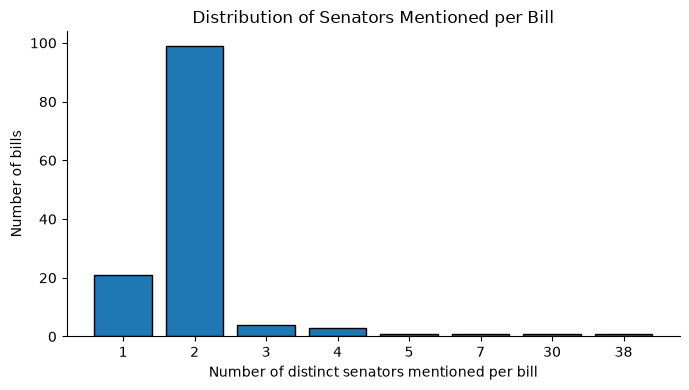

In [123]:
# Calculate the distribution of number of senators mentioned per bill

senator_distribution = (
    senator_bill_data["number_of_senators"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of senators mentioned per bill")
    .reset_index(name="Number of bills")
)

senator_distribution["Percentage"] = (
    senator_distribution["Number of bills"]
    / len(senator_bill_data) * 100
)

# Display the results

display(
    senator_distribution.style
    .format({"Percentage": "{:.1f}%"})
    .hide(axis="index")
    .set_caption("Distribution of distinct senators mentioned per bill")
)

# Show plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    senator_distribution["Number of senators mentioned per bill"].astype(str),
    senator_distribution["Number of bills"],
    edgecolor="black"
)

ax.set_xlabel("Number of distinct senators mentioned per bill")
ax.set_ylabel("Number of bills")
ax.set_title("Distribution of Senators Mentioned per Bill")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


In [124]:
# Display the number of different coauthors per senator

coauthor_data = senator_bill_data.dropna(
    subset=["Senator 1", "Senator 2"]
).copy()

coauthor_counts = (
    coauthor_data.groupby("Senator 1")["Senator 2"]
    .nunique()
    .reset_index(name="Number of different coauthors")
    .sort_values("Number of different coauthors", ascending=False)
)

# Display the top 20 senators with the highest numbers of different coauthors
display(coauthor_counts.head(20))

,Senator 1,Number of different coauthors
9,McConnell,38
1,Cornyn,9
12,Murkowski,6
0,Braun,5
11,Moran,4
13,Paul,3
16,Sasse,3
21,Thune,3
8,Lee,2
4,Fischer,2


### 4. Additional Insight

The number of senators mentioned in an amendment action may be associated with the amount of recorded activity surrounding its bill.

To explore this, I compare the total number of action records associated with bills across groups defined by the number of senators mentioned. 

Number of distinct senators across amendment actions,Number of bills,Mean total actions,Median total actions
1,21,2.5,2.0
2,99,3.1,2.0
3,4,13.5,11.5
4,3,10.0,7.0
5,1,8.0,8.0
7,1,7.0,7.0
30,1,34.0,34.0
38,1,187.0,187.0


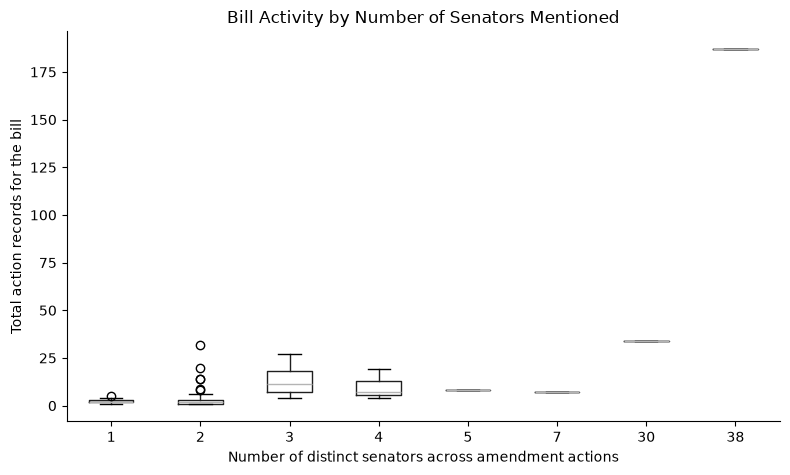

In [125]:
# Count the total action records associated with each bill

actions_per_bill = (
    bills_actions.groupby("bill")
    .size()
    .reset_index(name="Total actions for bill")
)

# Reduce the amendment subset to one row per bill
# Use the number of distinct senators across amendment actions

senator_counts_per_bill = (
    senator_bill_data.groupby("bill")["number_of_senators"]
    .max()
    .reset_index()
    .rename(columns={
        "number_of_senators": "Number of distinct senators across amendment actions"
    })
)

# Merge bill-level data, ensuring each bill appears only once

insight_data = senator_counts_per_bill.merge(
    actions_per_bill,
    on="bill",
    how="left",
    validate="one_to_one"
)

# Summarise overall bill activity by the senator-count group
insight_table = (
    insight_data.groupby("Number of distinct senators across amendment actions")
    ["Total actions for bill"]
    .agg(
        Number_of_bills="count",
        Mean_actions="mean",
        Median_actions="median"
    )
    .reset_index()
    .rename(columns={
        "Number_of_bills": "Number of bills",
        "Mean_actions": "Mean total actions",
        "Median_actions": "Median total actions"
    })
)

display(
    insight_table.style
    .format({
        "Mean total actions": "{:.1f}",
        "Median total actions": "{:.1f}"
    })
    .hide(axis="index")
    .set_caption("Bill activity by number of distinct senators across amendment actions")
)

# Compare the distribution of total actions across groups.
fig, ax = plt.subplots(figsize=(8, 5))

insight_data.boxplot(
    column="Total actions for bill",
    by="Number of distinct senators across amendment actions",
    ax=ax,
    grid=False
)

ax.set_xlabel("Number of distinct senators across amendment actions")
ax.set_ylabel("Total action records for the bill")
ax.set_title("Bill Activity by Number of Senators Mentioned")
fig.suptitle("")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()